# arXiv topic exploration

One year of stat.ML papers (26 Nov 2025 – 24 Nov 2026), from fetch_arxiv.py

## 1. Load the data

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/papers.csv")
print(len(df))
df.head()

7624


,id,title,link,published,abstract,primary_category,categories
0,2611.33064v1,U-Statistics-Powered LLM Reasoning,https://arxiv.org/abs/2611.33064v1,2026-11-24T18:05:01Z,"Since its introduction by DeepSeek, group rela...",cs.LG,cs.LG;stat.ML
1,2611.33036v1,Towards Realistic Evaluation of Uncertainty Qu...,https://arxiv.org/abs/2611.33036v1,2026-11-24T17:48:54Z,Large language models (LLMs) provide a flexibl...,cs.IR,cs.IR;cs.CL;cs.LG;stat.ML
2,2611.32947v1,Online V-Learning with Adaptive Longitudinal Data,https://arxiv.org/abs/2611.32947v1,2026-11-24T16:51:09Z,Reinforcement learning methods for estimating ...,stat.ML,stat.ML;cs.LG;math.ST;stat.AP;stat.ME
3,2611.32945v1,PHM-ensemble: Scalable and Stable Probabilisti...,https://arxiv.org/abs/2611.32945v1,2026-11-24T16:47:39Z,Clustering is a foundational tool for explorat...,stat.ML,stat.ML;cs.LG;q-bio.QM;stat.ME
4,2611.32762v1,SGD with Large Learning Rates: General Analysi...,https://arxiv.org/abs/2611.32762v1,2026-11-24T15:01:49Z,Stochastic Gradient Descent lies at the core o...,cs.LG,cs.LG;cs.AI;math.OC;stat.ML


## 2. Primary categories

In [16]:
df["primary_category"].value_counts(normalize=True).head(10)

primary_category
stat.ML    0.386280
cs.LG      0.338667
stat.ME    0.071485
math.ST    0.037907
math.OC    0.026364
cs.AI      0.014559
cs.CL      0.010362
cs.CV      0.009706
econ.EM    0.008919
stat.CO    0.008132
Name: proportion, dtype: float64

38.6% of papers are stat.ML and 33.9% are cs.LG, whereas the next one is only 7%. These two are by far the main primary categories. I'm keeping all papers, because cross-listed papers are still part of stat.ML, more papers gives BERTopic more to work with, and I can compare the two groups later.

	## 3. Papers per month

C:\Users\Manni\AppData\Local\Temp\ipykernel_20532\4009952248.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["published"].dt.to_period("M")


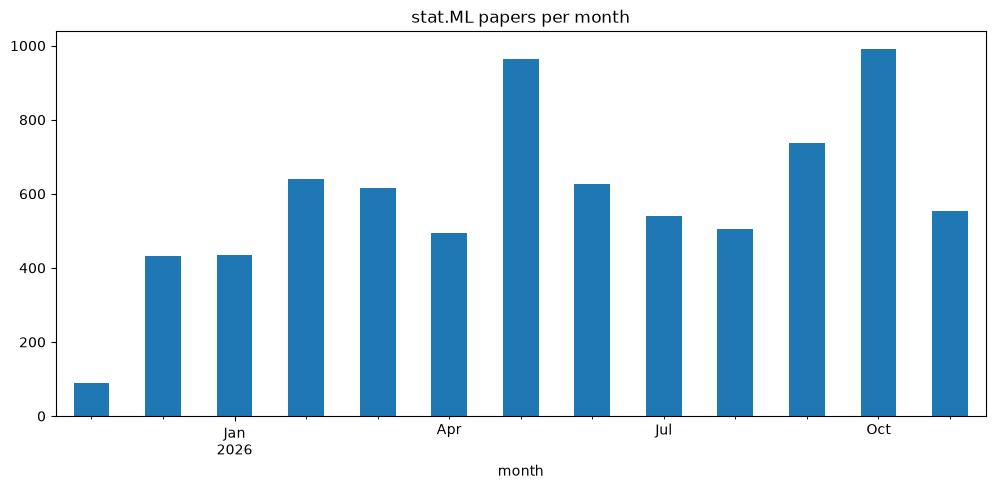

In [17]:
df["published"] = pd.to_datetime(df["published"])
df["month"] = df["published"].dt.to_period("M")
df["month"].value_counts().sort_index().plot(kind="bar", figsize=(12, 5), title="stat.ML papers per month")
plt.show()

There are two main peaks, in May (~960) and October (~990). These likely line up with major ML conference deadlines: NeurIPS submissions are due around May, and ICLR's around late September to early October. Researchers probably post their papers to arXiv around when they submit them. December and January are the quietest complete months (~430), most likely due to the holiday season.

The first and last bars are partial months: November 2025 only covers the 26th onwards, and November 2026 stops on the 24th. I'll leave both out when comparing topics month by month.


## 4. Abstract length

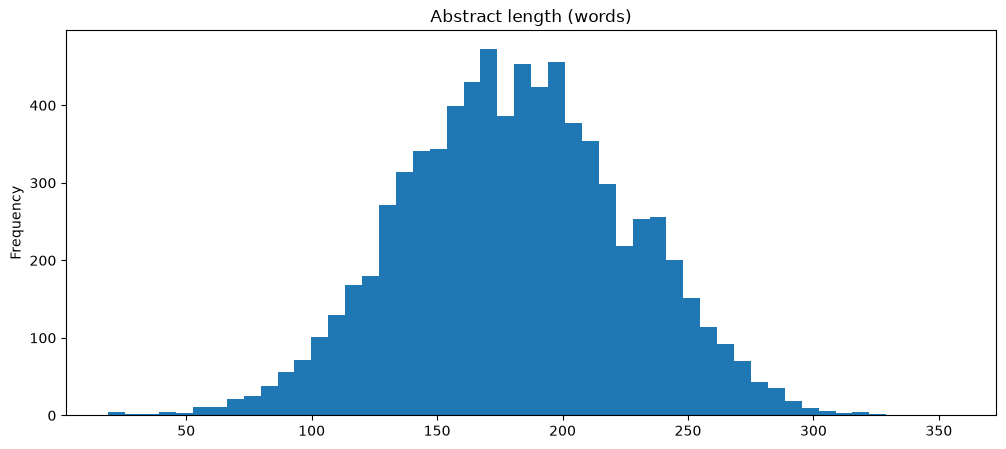

count    7624.000000
mean      181.405168
std        45.036635
min        19.000000
25%       150.000000
50%       181.000000
75%       212.000000
max       356.000000
Name: abstract_words, dtype: float64


,id,title,abstract_words,abstract
3362,2606.30500v1,Doubly Robust Adaptive Conformal Inference for...,19,We propose doubly robust adaptive conformal in...
1156,2610.15690v1,Notes on Uniform Policy Score Bounds and Lipsc...,20,We establish uniform score bounds and Lipschit...
2681,2608.07618v1,Stochastic gradient descent with discontinuity...,20,Stochastic gradient descent for a loss functio...
4955,2604.26550v1,Large-scale semi-supervised learning with onli...,22,"We introduce Sparse-HFS, a scalable algorithm ..."
3812,2606.07213v1,Principal Component Analysis for Multivariate ...,23,This chapter explores ways to reduce the dimen...


In [25]:
df["abstract_words"] = df["abstract"].str.split().str.len()

df["abstract_words"].plot(kind="hist", bins=50, figsize=(12, 5), title="Abstract length (words)")
plt.show()

print(df["abstract_words"].describe())
df.nsmallest(5, "abstract_words")[["id", "title", "abstract_words", "abstract"]]

Across 7,624 papers, abstract length is roughly bell-shaped around 180 words, with a standard deviation of 45. The middle 50% of papers are between 150 and 212 words. None are empty or broken (the shortest is 19 words), so no papers are removed.

## 5. Cleaning the text

In [19]:
print("LaTeX ($):", df["abstract"].str.contains(r"\$").mean())
print("Line breaks in titles:", df["title"].str.contains("\n").mean())
print("Line breaks in abstracts:", df["abstract"].str.contains("\n").mean())

LaTeX ($): 0.3268625393494229
Line breaks in titles: 0.0
Line breaks in abstracts: 0.07646904512067157


About 1/3 of abstracts (32.7%) contain LaTeX. This needs cleaning, otherwise BERTopic may produce topics labelled with words like mathcal, frac or mathbb, which are not ideas. 7.6% of abstracts contain line breaks, which will be replaced with spaces. All titles are clean.

In [26]:
latex = df["abstract"].str.findall(r"\$[^$]*\$").explode().dropna()
print(latex.sample(15, random_state=1))

1290    $O(e^{Λ_K}/K)$
2390               $T$
1332            $90\%$
3831       $ξ^2_\star$
5753          $Ω(K/W)$
2285         $[0,1]^d$
6745               $ε$
2670               $B$
6533               $h$
3028               $p$
5031               $D$
2390       $Ω(\log T)$
4568            $0.99$
3547             $5/5$
1977               $L$
Name: abstract, dtype: str


Most of the LaTeX is single symbols like $T$ or $p$, with some formulas and a few numbers. None of it tells BERTopic what a paper is about, so I removed everything between $ signs.

In [21]:
df["clean_abstract"] = df["abstract"].str.replace(r"\$[^$]*\$", "", regex=True).str.replace("\n", " ").str.replace(r"\s+", " ", regex=True).str.strip()
df["text"] = df["title"] + ". " + df["clean_abstract"]

print(df["clean_abstract"].str.contains(r"\$").mean())
print(df["text"].iloc[0])
df.to_csv("data/papers_clean.csv", index=False)

0.0007869884575026233
U-Statistics-Powered LLM Reasoning. Since its introduction by DeepSeek, group relative policy optimization (GRPO) has been widely adopted for training large reasoning models and agents, spurring a proliferation of its variants. Yet the group size, a crucial hyperparameter in these GRPO-type algorithms, remains largely chosen by trial and error. Exploiting the U-statistic structure of GRPO's policy gradient, we recast the selection of the group size as a classical statistical problem of variance ratio estimation. This problem is particularly challenging when the denominator of the ratio is small, rendering naive plug-in estimators unstable. To address this challenge, we propose a pessimistic ratio estimator that accounts for the denominator's estimation uncertainty. We characterise the statistical properties of this estimator across three sample-size regimes. Empirically, using %a jackknife-based pessimistic rule on synthetic tasks from Reasoning Gym and real-world

After cleaning, about 6 of the 7,624 papers still contain a $ sign. Looking at them, 5 of them are dollar amounts and 1 of them is a laTex Fragment missed, which is not enough to affect topics so I'm leaving it. That's too few to affect the topics, so I'm leaving them.

## 6. Co-categories

In [ ]:
cats = df["categories"].str.split(";").explode()
cats.value_counts().head(15)
(cats.value_counts() / len(df)).head(15)

,0
261,mplies a counterfactual net increase of $165.8...
870,impact with a recoverable-opportunity ($) met...
2261,1% (from a baseline of 13%) would cost $211 B...
2641,pass@2 at a computed inference cost of \$0.000...
4436,ave reduced total treatment costs by CAN$2.5-4...
5606,FLOP training budget and \412K-\α\neq β$). Ch...


82% of stat.ML papers are also tagged cs.LG, so stat.ML and machine learning in computer science overlap massively, which matches the primary categories earlier. Every other category is much smaller. There's a statistics side (stat.ME 15%, math.ST 12%) and an optimisation side (math.OC 8%), plus small groups like NLP and computer vision.